## Exploring dataset consisting of Landsat and Sentinel Multispectral Images

In [1]:
import time

import numpy as np
import torch
import torch.nn as nn
from matplotlib.colors import ListedColormap

import deepinv as dinv
from deepinv.loss.metric import SSIM

#from PnP_DRUNet_plot import clean_and_normalize


DATASET_PATH    = "data/T_Lhasa_L2S_RealDataset_full.pt"     # saved TensorDataset (observations, references)
CHECKPOINT_PATH = "checkpoints/checkpoint_epoch_DRUNetFixNoise_1495.pth"  # fine-tuned DRUNet (see denoiser_training.py)

IMG_SIZE    = [4, 300, 300]  # (channels, height, width)

/Users/mattia/Documents/CentraleSupelec/3A/projetRecherche3A/PnP_Reconstruction/PnP-SR-for-multispectral-satellite-imagery/.venvmac/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset = torch.load(DATASET_PATH, weights_only=False)

In [3]:
landsat_data, sentinel_data = dataset
print(f"Landsat Images (batch, channels, D, D) {landsat_data.shape}, Sentinel Images: {sentinel_data.shape}")

Landsat Images (batch, channels, D, D) torch.Size([1200, 4, 100, 100]), Sentinel Images: torch.Size([1200, 4, 300, 300])


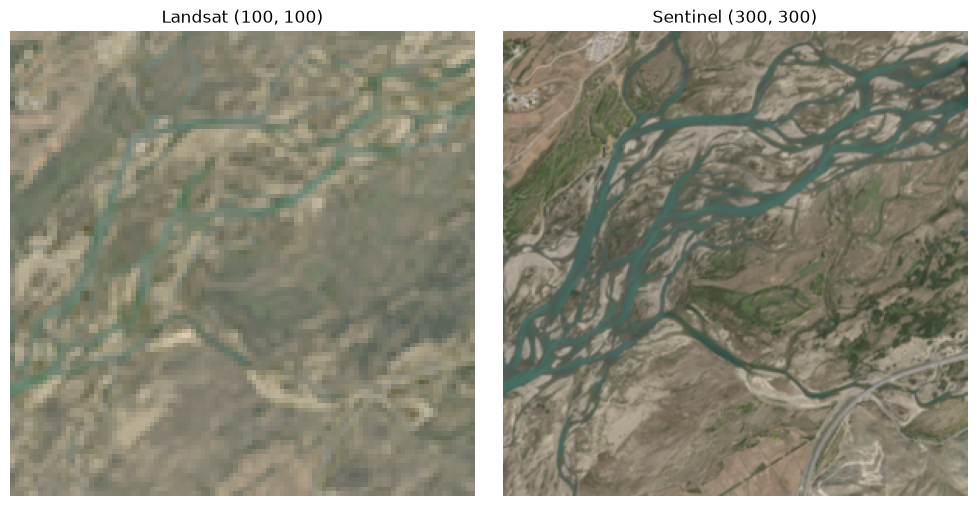

In [4]:
import matplotlib.pyplot as plt

def clean_and_normalize(image):
    """Same as in PnP_DRUNet_plot.py: replace NaN/inf, then min-max rescal
e to [0, 1]."""
    image = torch.nan_to_num(image, nan=0.0, posinf=1.0, neginf=0.0)
    return (image - image.min()) / (image.max() - image.min())

def to_rgb(img):
    """(4, H, W) tensor with channels (B, G, R, NIR) -> (H, W, 3) RGB arra
y, gamma-corrected for display."""
    img = clean_and_normalize(img)
    return (img[[2, 1, 0]] ** 0.5).permute(1, 2, 0).numpy()

idx = 0  # index of the Landsat/Sentinel pair to show
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(to_rgb(landsat_data[idx]))
axes[0].set_title(f"Landsat {tuple(landsat_data.shape[-2:])}")
axes[1].imshow(to_rgb(sentinel_data[idx]))
axes[1].set_title(f"Sentinel {tuple(sentinel_data.shape[-2:])}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()